# Movie Revenue Correlation

Which features of a movie move together with its gross revenue?

Each row is one film (1980 to 2020) with its budget, gross revenue, rating, genre, score, votes, director, star, company and more.

*Revised October 2026: fixed the release-year column, the missing-data percentages and the scatter plot labels, and trimmed long outputs.*

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (12, 8)

df = pd.read_csv('movies.csv')
df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


## 1. Check for missing data
The share of blank values in each column. Budget is the big gap.

In [2]:
for col in df.columns:
    pct_missing = df[col].isnull().mean()
    print(f'{col}: {pct_missing:.1%}')

name: 0.0%
rating: 1.0%
genre: 0.0%
year: 0.0%
released: 0.0%
score: 0.0%
votes: 0.0%
director: 0.0%
writer: 0.0%
star: 0.0%
country: 0.0%
budget: 28.3%
gross: 2.5%
company: 0.2%
runtime: 0.1%


## 2. Get the real release year
`released` looks like "June 13, 1980 (United States)", so the year is pulled out as the four-digit number.

In [3]:
df['year_correct'] = df['released'].str.extract(r'(\d{4})').astype('Int64')
df[['name', 'year', 'released', 'year_correct']].head()

,name,year,released,year_correct
0,The Shining,1980,"June 13, 1980 (United States)",1980
1,The Blue Lagoon,1980,"July 2, 1980 (United States)",1980
2,Star Wars: Episode V - The Empire Strikes Back,1980,"June 20, 1980 (United States)",1980
3,Airplane!,1980,"July 2, 1980 (United States)",1980
4,Caddyshack,1980,"July 25, 1980 (United States)",1980


## 3. Budget vs gross revenue
Each dot is a film. The line is the best fit.

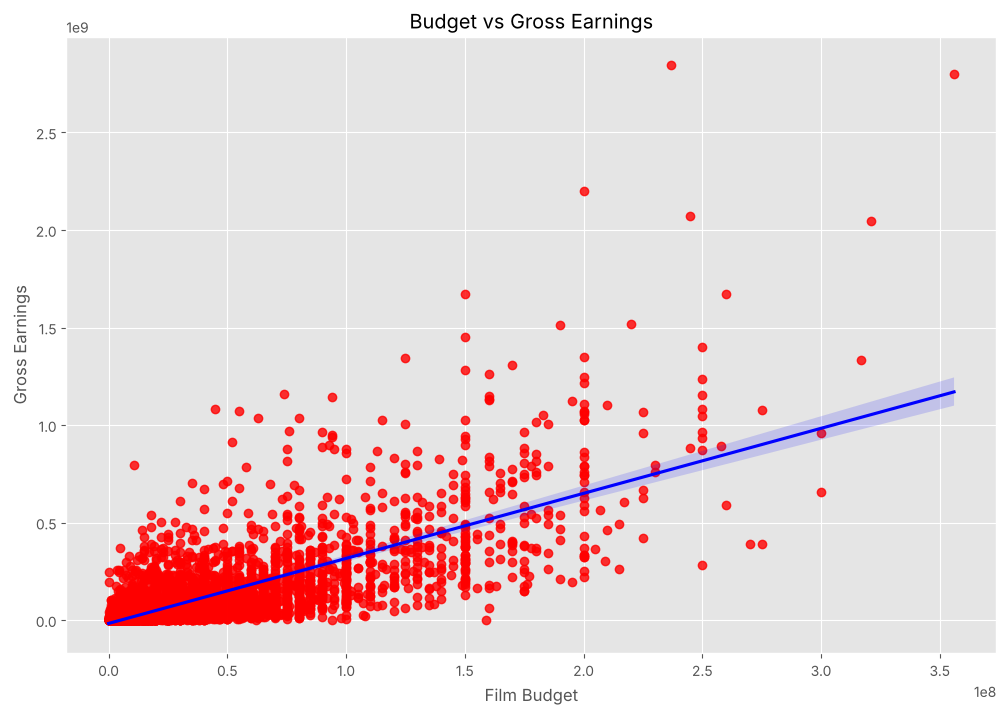

In [4]:
df = df.sort_values(by='gross', ascending=False)

sns.regplot(x='budget', y='gross', data=df, scatter_kws={'color': 'red'}, line_kws={'color': 'blue'})
plt.title('Budget vs Gross Earnings')
plt.xlabel('Film Budget')
plt.ylabel('Gross Earnings')
plt.show()

## 4. Correlation between the numeric columns
Pearson correlation runs from -1 to 1. Values near 1 mean two columns rise together.

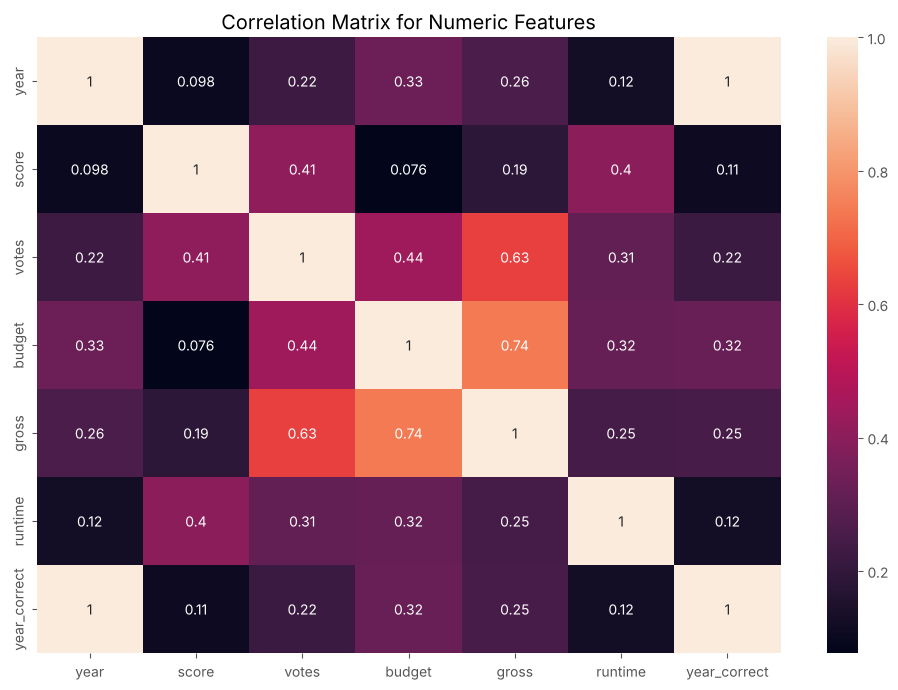

In [5]:
correlation_matrix = df.corr(method='pearson', numeric_only=True)
sns.heatmap(correlation_matrix, annot=True)
plt.title('Correlation Matrix for Numeric Features')
plt.show()

## 5. Pairs with a correlation above 0.5

In [6]:
pairs = correlation_matrix.unstack().sort_values(ascending=False)
pairs = pairs[(pairs > 0.5) & (pairs < 1)].drop_duplicates()
pairs

year    year_correct    0.997415
budget  gross           0.740395
gross   votes           0.630757
dtype: float64

## 6. Does the production company matter?
The original version turned text columns into category codes and correlated them. Those codes are just alphabetical numbers, so that test isn't meaningful. Here is a fairer look: average gross for the companies with the most films.

In [7]:
top_companies = df['company'].value_counts().head(10).index
(df[df['company'].isin(top_companies)]
   .groupby('company')['gross'].agg(['count', 'mean'])
   .sort_values('mean', ascending=False)
   .style.format({'mean': '${:,.0f}'}))

,count,mean
company,,
Walt Disney Pictures,123,"$295,348,681"
Warner Bros.,333,"$169,643,909"
Twentieth Century Fox,240,"$167,737,724"
Universal Pictures,376,"$139,665,396"
Columbia Pictures,332,"$129,545,004"
Paramount Pictures,319,"$126,939,208"
New Line Cinema,174,"$114,274,699"
Touchstone Pictures,132,"$89,362,368"
Metro-Goldwyn-Mayer (MGM),123,"$75,042,521"


## Findings
- **Budget** has the strongest relationship with gross revenue (about 0.74).
- **Votes** come next (about 0.63).
- About a quarter of films have no budget, so the budget result rests on the rest.
- **Production company** does matter on average: among the ten companies with the most films, average gross ranges from about $60M to about $295M. The original category-code test hid this. Big studios also spend more, so budget explains part of the gap.
- Correlation shows that two things move together, not that one causes the other.